<a href="https://colab.research.google.com/github/akp4256/Python-Code/blob/main/Quick_Bite_Case_Study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [221]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [222]:
data = pd.read_csv('/content/quickbite_customers.csv')

In [223]:
data

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,QB101995,2023-08-07,Jaipur,2,Male,iOS,Influencer,18.0,39.4,9,42.7,254.0,3.7,36.2,6.0,Basic,13,2704.0
1996,QB101996,2025-06-07,Delhi,1,Male,iOS,Search Ads,29.0,17.0,7,20.7,249.0,4.5,24.1,6.0,Basic,17,3723.0
1997,QB101997,2025-10-15,Bengaluru,1,Male,Android,Paid Social,45.0,12.7,18,38.0,528.0,NaN,2.9,1.0,Silver,24,13736.0
1998,QB101998,2025-02-22,Indore,3,Male,iOS,Influencer,NaN,20.5,21,68.8,314.0,4.3,29.4,8.0,Platinum,37,14368.0


In [224]:
data['signup_date'] = pd.to_datetime(data['signup_date'])

In [225]:
data.describe()

,signup_date,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
count,2000,2000.000000,1861.000000,2000.000000,2000.00000,1920.000000,1892.000000,1742.000000,1896.000000,2000.000000,2000.00000,2000.000000
mean,2024-05-28 18:57:35.999999744,1.600500,31.926384,29.507300,13.93200,34.991198,417.577696,4.290356,22.499947,18.599500,34.89650,12995.852000
min,2023-01-01 00:00:00,1.000000,0.000000,12.000000,2.00000,15.600000,57.000000,1.000000,0.000000,0.000000,5.00000,523.000000
25%,2023-09-18 18:00:00,1.000000,27.000000,20.775000,11.00000,26.200000,215.000000,4.000000,16.200000,5.000000,17.00000,4085.750000
50%,2024-05-29 12:00:00,1.000000,32.000000,29.500000,14.00000,32.250000,315.500000,4.400000,22.400000,12.000000,24.00000,7142.000000
75%,2025-02-15 06:00:00,2.000000,37.000000,37.925000,16.00000,40.500000,458.250000,4.700000,28.500000,26.000000,32.00000,12781.250000
max,2025-11-05 00:00:00,3.000000,150.000000,46.600000,29.00000,500.000000,32000.000000,5.000000,55.900000,125.000000,400.00000,855443.000000
std,NaN,0.772138,7.619334,9.981302,3.77856,19.486015,1133.673898,0.609572,9.483931,18.983606,49.27424,30336.382856


In [226]:
data.head()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,QB100000,2023-11-27,Lucknow,2,Female,Android,Referral,21.0,35.6,13,45.3,572.0,NaN,21.6,4.0,Basic,17,8675.0
1,QB100001,2025-05-26,Bengaluru,1,Female,iOS,Influencer,43.0,17.4,11,21.9,329.0,4.9,0.0,13.0,Basic,24,7896.0
2,QB100002,2023-02-06,Indore,3,Male,iOS,Referral,39.0,45.4,12,47.9,118.0,3.8,17.8,1.0,Basic,17,1826.0
3,QB100003,2024-04-09,Jaipur,2,Female,Android,Paid Social,34.0,31.2,13,26.4,303.0,NaN,42.9,7.0,Basic,379,90202.0
4,QB100004,2025-04-12,Mumbai,1,Male,Android,Search Ads,33.0,18.9,17,19.4,191.0,4.0,29.2,12.0,Basic,17,2773.0


In [227]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 18 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             2000 non-null   object        
 1   signup_date             2000 non-null   datetime64[ns]
 2   city                    2000 non-null   object        
 3   city_tier               2000 non-null   int64         
 4   gender                  1894 non-null   object        
 5   device_type             2000 non-null   object        
 6   acquisition_channel     2000 non-null   object        
 7   age                     1861 non-null   float64       
 8   tenure_months           2000 non-null   float64       
 9   app_sessions_per_month  2000 non-null   int64         
 10  delivery_time_min       1920 non-null   float64       
 11  avg_order_value         1892 non-null   float64       
 12  customer_rating         1742 non-null   float64 

In [228]:
data.shape

(2000, 18)

In [229]:
data.isna()

,customer_id,signup_date,city,city_tier,gender,device_type,acquisition_channel,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,membership,orders_last_12m,annual_spend
0,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
1,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
2,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
3,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
4,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1995,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1996,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False,False
1997,False,False,False,False,False,False,False,False,False,False,False,False,True,False,False,False,False,False
1998,False,False,False,False,False,False,False,True,False,False,False,False,False,False,False,False,False,False


In [230]:
data.isna().sum()

,0
customer_id,0
signup_date,0
city,0
city_tier,0
gender,106
device_type,0
acquisition_channel,0
age,139
tenure_months,0
app_sessions_per_month,0


In [231]:
data.isna().mean() * 100

,0
customer_id,0.00
signup_date,0.00
city,0.00
city_tier,0.00
gender,5.30
device_type,0.00
acquisition_channel,0.00
age,6.95
tenure_months,0.00
app_sessions_per_month,0.00


In [232]:
missing_values = pd.DataFrame({'missing_count': data.isna().sum(), 'missing_percentage': data.isna().mean() * 100})
missing_values

,missing_count,missing_percentage
customer_id,0,0.00
signup_date,0,0.00
city,0,0.00
city_tier,0,0.00
gender,106,5.30
device_type,0,0.00
acquisition_channel,0,0.00
age,139,6.95
tenure_months,0,0.00
app_sessions_per_month,0,0.00


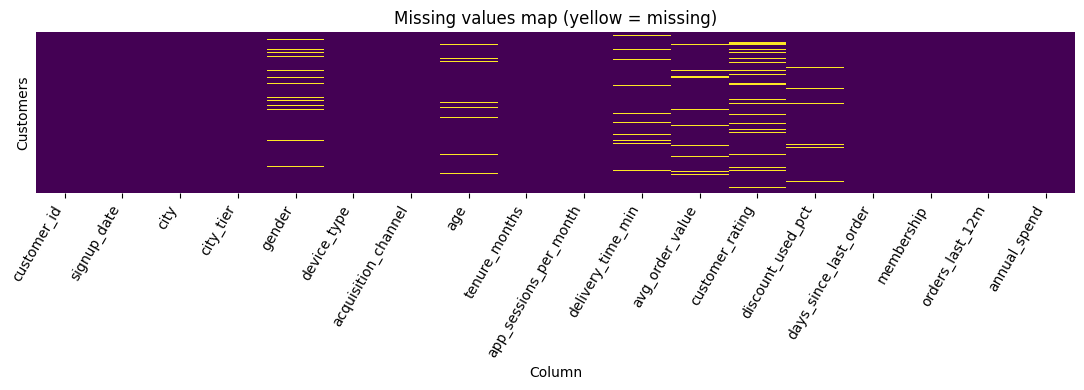

In [233]:
plt.figure(figsize=(11,4))
sns.heatmap(data.isna(), cbar = False, yticklabels = False, cmap = 'viridis')
plt.title('Missing values map (yellow = missing)')
plt.xlabel('Column')
plt.ylabel('Customers')
plt.xticks(rotation = 60, ha = 'right')
plt.tight_layout()
plt.show()

**Explanation**:

Only some columns have gaps. describe() also shows odd values, like an age far above 100 or negative, a delivery time of hundreds of minutes, and a huge order value.

# Task 1: Missing Value Imputation

In [234]:
df = data.copy()

In [235]:
# age : we will fill missing values with median
df['age'] = df.age.fillna(df.age.median())
df['age']

,age
0,21.0
1,43.0
2,39.0
3,34.0
4,33.0
...,...
1995,18.0
1996,29.0
1997,45.0
1998,32.0


Explanation:


*   Age is roughly normal, so the mean and median will be close once the errors are removed. The median is still the safer choice because it holds up if the cleaning missed anything.
*   List itemFilling with the median adds one spike at a single age. That is acceptable here because only a small share of ages is missing, and the before/after KDE should show almost no change in shape.




In [236]:
# delivery_time_min: we will fill missing values with median
df['delivery_time_min'] = df.delivery_time_min.fillna(df.delivery_time_min.median())
df['delivery_time_min']

,delivery_time_min
0,45.3
1,21.9
2,47.9
3,26.4
4,19.4
...,...
1995,42.7
1996,20.7
1997,38.0
1998,68.8


Explanantion:


*   Delivery time is right-skewed: most deliveries are quick and a few are very slow. The mean is pulled up by that tail.
*   A mean fill would give missing customers a delivery time slower than a typical customer experiences. The median keeps the fill at the centre of the data.



In [237]:
# avg_order_value: we will fill missing values with median
df['avg_order_value'] = df.avg_order_value.fillna(df.groupby('city_tier').avg_order_value.transform('median'))
df['avg_order_value']

,avg_order_value
0,572.0
1,329.0
2,118.0
3,303.0
4,191.0
...,...
1995,254.0
1996,249.0
1997,528.0
1998,314.0


Explanation:


*   Basket size is log-normal (many modest baskets, a few huge ones), so the median is better than the mean for the same reason as delivery time.
*   Group-wise vs global: customers in metro cities and tier-3 cities don’t order the same amounts. A global median would pull everyone toward one number. A group median keeps tier differences. Check it with df.groupby('city_tier').avg_order_value.median(). If the medians differ clearly, group-wise is justified.



In [238]:
#customer_rating
print('Global Median :',df.customer_rating.median(),'| By Tier Median:',df.groupby('city_tier').customer_rating.median().to_dict())
df['customer_rating'] = df.customer_rating.fillna(df.groupby('city_tier').customer_rating.transform('median'))
df['customer_rating']

Global Median : 4.4 | By Tier Median: {1: 4.4, 2: 4.5, 3: 4.4}


,customer_rating
0,4.5
1,4.9
2,3.8
3,4.5
4,4.0
...,...
1995,3.7
1996,4.5
1997,4.4
1998,4.3


Explanation:


*   Ratings are left-skewed (most customers rate high), so the median is a better centre than the mean, which the low ratings pull down. Is missingness related to long delivery times?
*   If so, the data is not missing at random. Unhappy customers skip rating, so the observed ratings are probably too optimistic, and filling with the median pushes missing customers toward a “typical” rating that is likely higher than their real experience.

*   Comparing the global median with the tier medians shows whether the tier group adds anything. If they are nearly equal, the choice matters little.



In [239]:
# discount: compare mean vs median
print('discount mean vs median:',round(data.discount_used_pct.mean(),2),round(data.discount_used_pct.median(),2))
df['discount_used_pct']=df.discount_used_pct.fillna(df.discount_used_pct.median())
df['discount_used_pct']

discount mean vs median: 22.5 22.4


,discount_used_pct
0,21.6
1,0.0
2,17.8
3,42.9
4,29.2
...,...
1995,36.2
1996,24.1
1997,2.9
1998,29.4


Explanation:


*   Compare mean and median first. If the mean is clearly higher, the distribution is right-skewed (a few heavy discount users), so the median is the better fill. If they are almost equal, either fill is fine and the result barely changes.
*   This column has one of the higher missing rates. If the gaps hide a real pattern (for example, customers who never use offers), a single fill value masks it.



In [240]:
# gender
df['gender']=df.gender.fillna('Unknown')
df['gender']

,gender
0,Female
1,Female
2,Male
3,Female
4,Male
...,...
1995,Male
1996,Male
1997,Male
1998,Male


Explanation:


*   “Unknown” is more honest: It keeps the gap visible and doesn’t distort the real counts. The cost is that you now have a fourth category to handle in any grouping.



In [241]:
cols=['age','delivery_time_min','avg_order_value','customer_rating','discount_used_pct']
compare = pd.DataFrame({'missing_before':data[cols].isna().sum(),'missing_after':df[cols].isna().sum(),
 'mean_before':data[cols].mean().round(2),'mean_after':df[cols].mean().round(2),
 'median_before':data[cols].median().round(2),'median_after':df[cols].median().round(2),
 'std_before':data[cols].std().round(2),'std_after':df[cols].std().round(2)})
compare.loc['gender', 'missing_before'] = data.gender.isna().sum()
compare.loc['gender', 'missing_after'] = df.gender.isna().sum()
compare

,missing_before,missing_after,mean_before,mean_after,median_before,median_after,std_before,std_after
age,139.0,0.0,31.93,31.93,32.00,32.00,7.62,7.35
delivery_time_min,80.0,0.0,34.99,34.88,32.25,32.25,19.49,19.10
avg_order_value,108.0,0.0,417.58,411.99,315.50,316.00,1133.67,1102.88
customer_rating,258.0,0.0,4.29,4.31,4.40,4.40,0.61,0.57
discount_used_pct,104.0,0.0,22.50,22.49,22.40,22.40,9.48,9.23
gender,106.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN


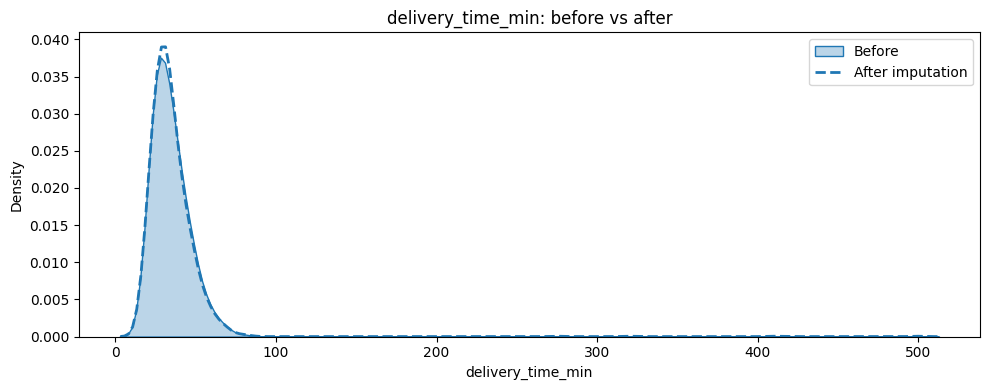

In [242]:
plt.figure(figsize=(10, 4))
sns.kdeplot(data['delivery_time_min'].dropna(), fill=True, alpha=0.3, label='Before')
sns.kdeplot(df['delivery_time_min'], linestyle='--', linewidth=2, label='After imputation')
plt.title('delivery_time_min: before vs after'); plt.legend()
plt.tight_layout()
plt.show()

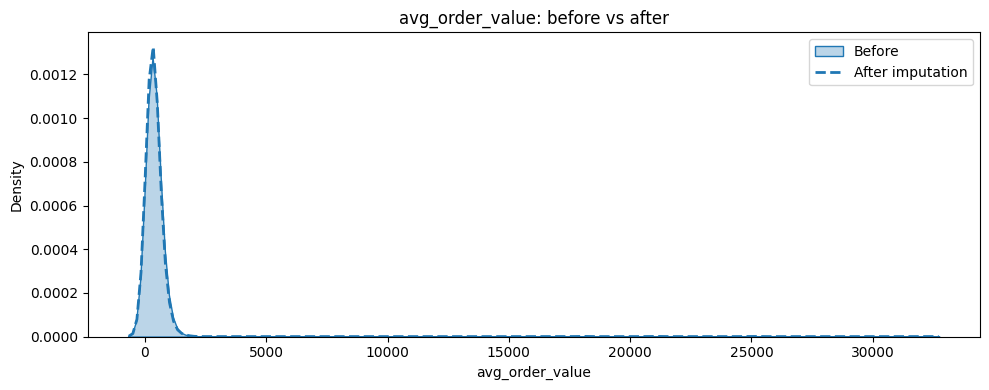

In [243]:
plt.figure(figsize=(10, 4))
sns.kdeplot(data['avg_order_value'].dropna(), fill=True, alpha=0.3, label='Before')
sns.kdeplot(df['avg_order_value'], linestyle='--', linewidth=2, label='After imputation')
plt.title('avg_order_value: before vs after'); plt.legend()
plt.tight_layout()
plt.show()

Overall Takeaway:


*   Median beats mean when data is skewed or has outliers, because the mean follows the tail.
*   Group-wise fills beat global fills when groups genuinely differ (order value by tier).

*   “Unknown” is more honest than guessing for categorical data like gender.
*   Missingness can carry information. Ratings are the clearest case, so the filled ratings should be trusted less.





# Task 2: Outlier Detection and Removal

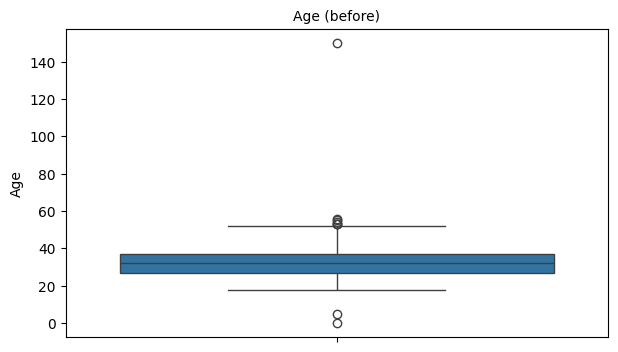

In [244]:
plt.figure(figsize = (7, 4))
sns.boxplot(data = data,y = "age")
plt.yticks(fontsize = 10)
plt.ylabel("Age", fontsize = 10)
plt.title("Age (before)", fontsize = 10)
plt.show()

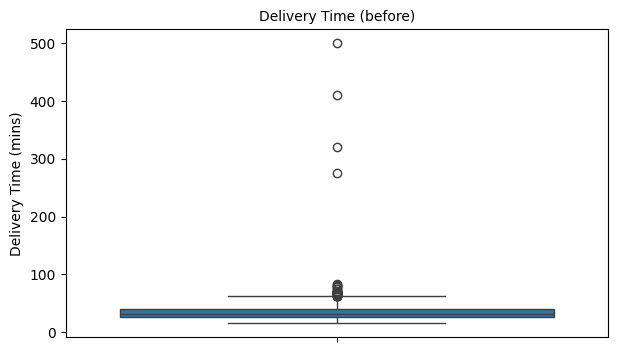

In [245]:
plt.figure(figsize = (7, 4))
sns.boxplot(data = data,y = "delivery_time_min")
plt.yticks(fontsize = 10)
plt.ylabel("Delivery Time (mins)", fontsize = 10)
plt.title("Delivery Time (before)", fontsize = 10)
plt.show()

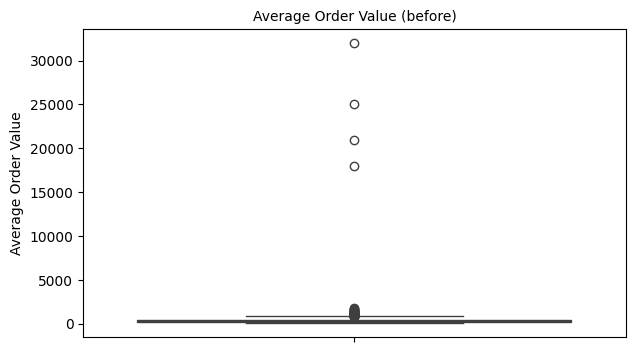

In [246]:
plt.figure(figsize = (7, 4))
sns.boxplot(data = data,y = "avg_order_value")
plt.yticks(fontsize = 10)
plt.ylabel("Average Order Value", fontsize = 10)
plt.title("Average Order Value (before)", fontsize = 10)
plt.show()

In [247]:
# ---- age ----
age = data['age'].dropna()
q1 = age.quantile(0.25)
q3 = age.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
z = (age - age.mean()) / age.std()
print('age | IQR fences:', round(low, 1), 'to', round(high, 1), '| IQR outliers:', ((age < low) | (age > high)).sum(), '| Z outliers:', (z.abs() > 3).sum())

# ---- delivery time ----
dt = data['delivery_time_min'].dropna()
q1 = dt.quantile(0.25)
q3 = dt.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
z = (dt - dt.mean()) / dt.std()
print('delivery_time | IQR fences:', round(low, 1), 'to', round(high, 1), '| IQR outliers:', ((dt < low) | (dt > high)).sum(), '| Z outliers:', (z.abs() > 3).sum())

# ---- order value ----
aov = data['avg_order_value'].dropna()
q1 = aov.quantile(0.25)
q3 = aov.quantile(0.75)
iqr = q3 - q1
low = q1 - 1.5 * iqr
high = q3 + 1.5 * iqr
z = (aov - aov.mean()) / aov.std()
print('avg_order_value| IQR fences:', round(low, 1), 'to', round(high, 1), '| IQR outliers:', ((aov < low) | (aov > high)).sum(), '| Z outliers:', (z.abs() > 3).sum())

age | IQR fences: 12.0 to 52.0 | IQR outliers: 9 | Z outliers: 5
delivery_time | IQR fences: 4.7 to 62.0 | IQR outliers: 46 | Z outliers: 4
avg_order_value| IQR fences: -149.9 to 823.1 | IQR outliers: 96 | Z outliers: 4


In [248]:
# age: impossible values -> missing
bad_age = (df['age'] < 15) | (df['age'] > 90)
df.loc[bad_age, 'age'] = np.nan

# delivery time: flag extremes, then cap them at the extreme fence (Q3 + 3*IQR)
d_q1 = df['delivery_time_min'].quantile(0.25)
d_q3 = df['delivery_time_min'].quantile(0.75)
d_fence = d_q3 + 3 * (d_q3 - d_q1)
df['delivery_extreme'] = (df['delivery_time_min'] > d_fence).astype(int)
df['delivery_time_min'] = df['delivery_time_min'].clip(upper=d_fence)

# order value: extreme errors on the log scale -> missing
log_aov = np.log(df['avg_order_value'])
l_q1 = log_aov.quantile(0.25)
l_q3 = log_aov.quantile(0.75)
l_fence = l_q3 + 3 * (l_q3 - l_q1)
bad_aov = log_aov > l_fence
df.loc[bad_aov, 'avg_order_value'] = np.nan

print('ages set to missing:', bad_age.sum())
print('delivery times flagged and capped:', df['delivery_extreme'].sum(), '(cap =', round(d_fence, 1), 'min)')
print('order values set to missing:', bad_aov.sum())

ages set to missing: 3
delivery times flagged and capped: 5 (cap = 80.9 min)
order values set to missing: 4


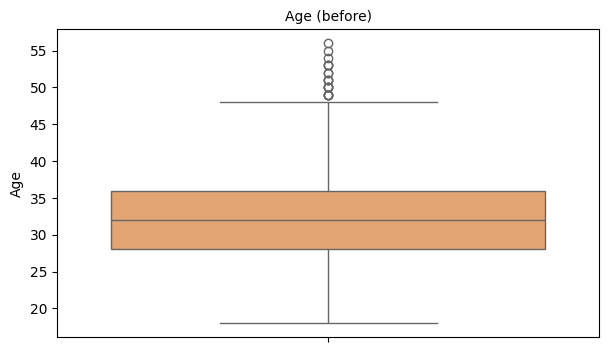

In [249]:
plt.figure(figsize = (7, 4))
sns.boxplot(data = df,y = "age", color='#f4a261')
plt.yticks(fontsize = 10)
plt.ylabel("Age", fontsize = 10)
plt.title("Age (before)", fontsize = 10)
plt.show()

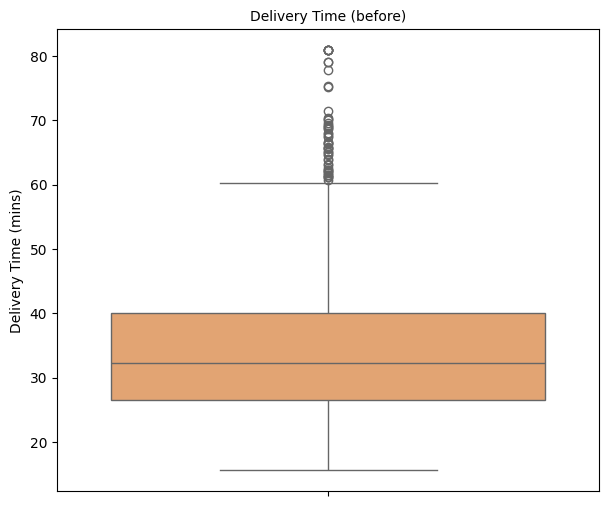

In [250]:
plt.figure(figsize = (7, 6))
sns.boxplot(data = df,y = "delivery_time_min", color='#f4a261')
plt.yticks(fontsize = 10)
plt.ylabel("Delivery Time (mins)", fontsize = 10)
plt.title("Delivery Time (before)", fontsize = 10)
plt.show()

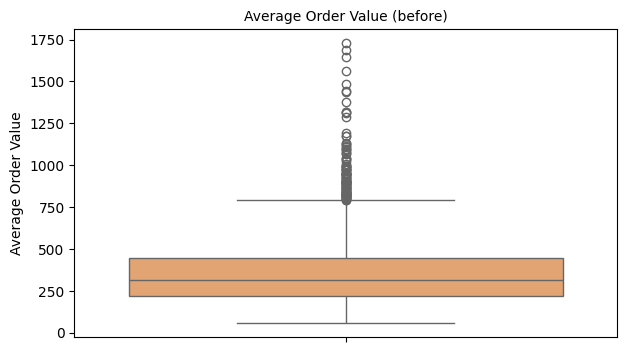

In [251]:
plt.figure(figsize = (7, 4))
sns.boxplot(data = df,y = "avg_order_value", color='#f4a261')
plt.yticks(fontsize = 10)
plt.ylabel("Average Order Value", fontsize = 10)
plt.title("Average Order Value (before)", fontsize = 10)
plt.show()

**Decisions(and why)**


*   **age**: values outside 15–90 are impossible (data-entry errors) → set to missing, then impute. A 150-year-old customer cannot be real.
*   **delivery_time_min**: very long deliveries may be real failures, so we do not delete them. We add a flag column delivery_extreme (for investigation) and **cap (winsorise)** at the 99th percentile of the non-extreme data so they don't distort means/KDEs.

*   **avg_order_value**: the true distribution is log-normal, so the plain IQR rule flags many genuine big baskets. We only treat values beyond the **extreme fence (Q3 + 3·IQR on the log scale)** as errors → set to missing, then impute.
*   **annual_spend**: keep. High spenders are genuine VIPs and the heavy tail is the business story

# Task 3: Distribution Shapes with KDE Plots

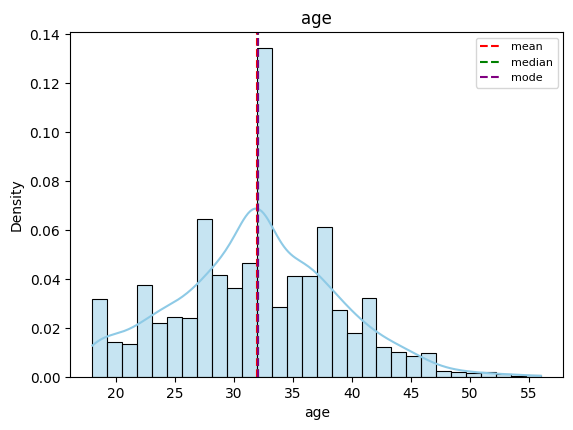

In [252]:
plt.figure(figsize=(16, 8))

plt.subplot(2, 3, 1)
sns.histplot(df['age'], kde=True, stat='density', color='#8ecae6')
plt.axvline(df['age'].mean(), color='red', linestyle='--', label='mean')
plt.axvline(df['age'].median(), color='green', linestyle='--', label='median')
plt.axvline(df['age'].round(0).mode()[0], color='purple', linestyle='--', label='mode')
plt.title('age'); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

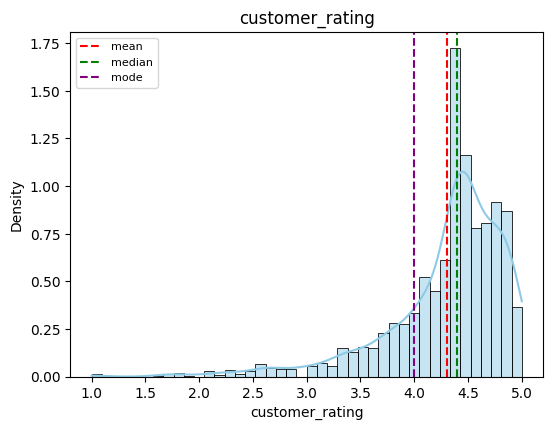

In [253]:
plt.figure(figsize=(16, 8))
plt.subplot(2, 3, 2)
sns.histplot(df['customer_rating'], kde=True, stat='density', color='#8ecae6')
plt.axvline(df['customer_rating'].mean(), color='red', linestyle='--', label='mean')
plt.axvline(df['customer_rating'].median(), color='green', linestyle='--', label='median')
plt.axvline(df['customer_rating'].round(0).mode()[0], color='purple', linestyle='--', label='mode')
plt.title('customer_rating'); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

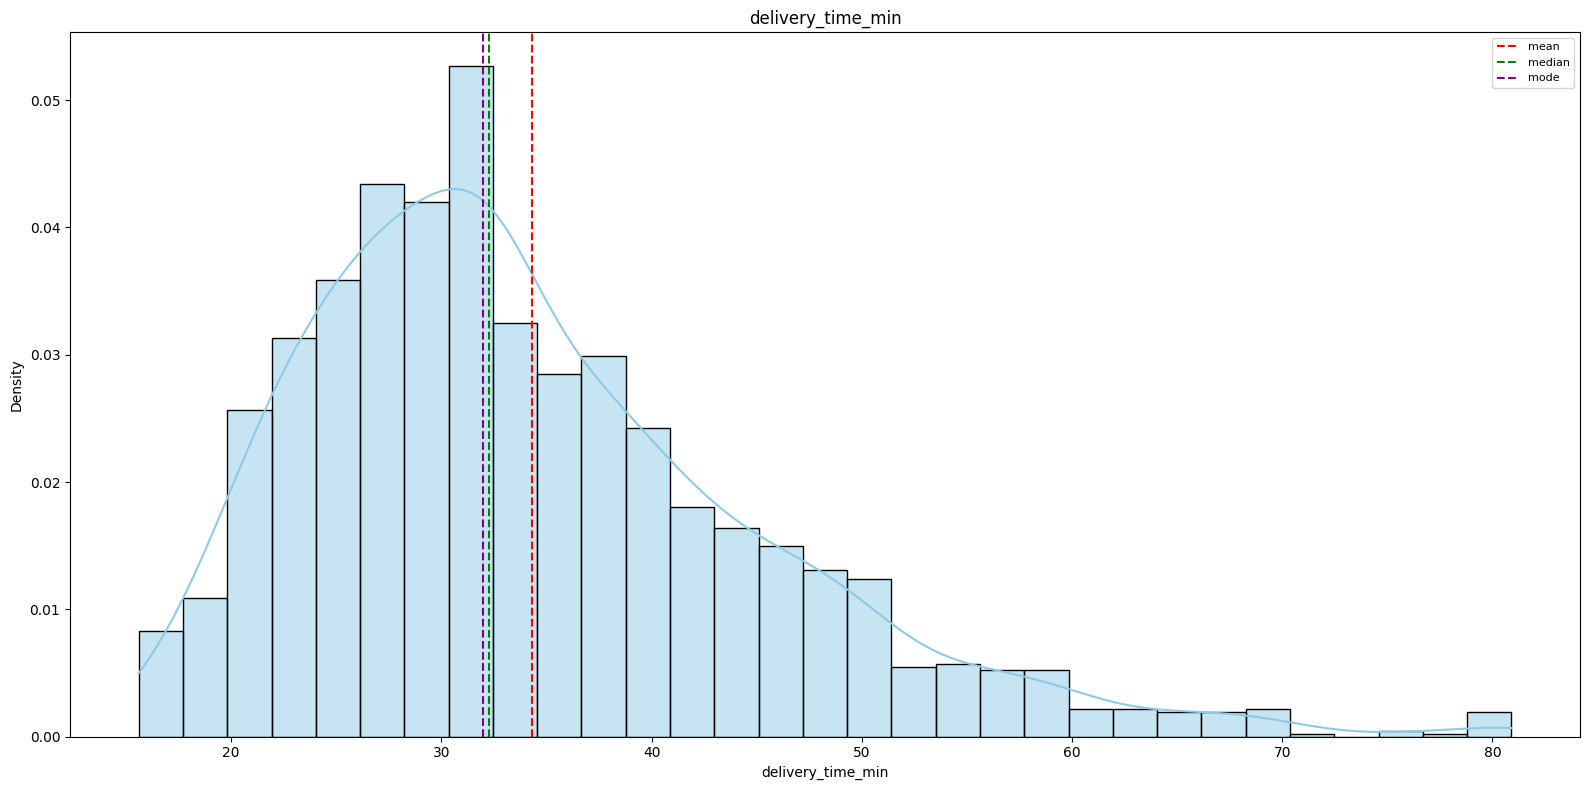

In [254]:
plt.figure(figsize=(16, 8))
sns.histplot(df['delivery_time_min'], kde=True, stat='density', color='#8ecae6')
plt.axvline(df['delivery_time_min'].mean(), color='red', linestyle='--', label='mean')
plt.axvline(df['delivery_time_min'].median(), color='green', linestyle='--', label='median')
plt.axvline(df['delivery_time_min'].round(0).mode()[0], color='purple', linestyle='--', label='mode')
plt.title('delivery_time_min'); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

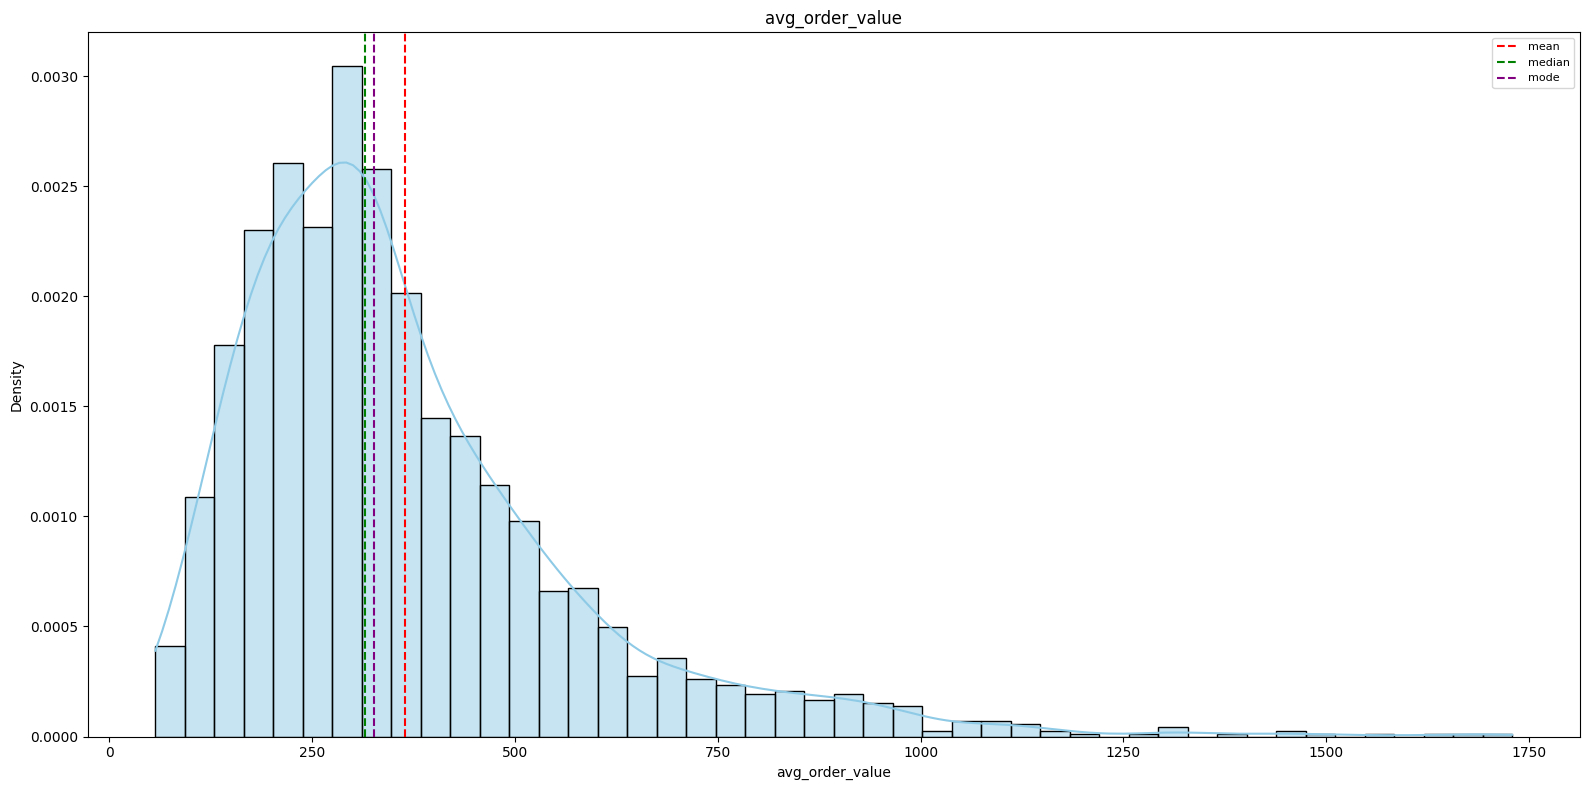

In [255]:
plt.figure(figsize=(16, 8))
sns.histplot(df['avg_order_value'], kde=True, stat='density', color='#8ecae6')
plt.axvline(df['avg_order_value'].mean(), color='red', linestyle='--', label='mean')
plt.axvline(df['avg_order_value'].median(), color='green', linestyle='--', label='median')
plt.axvline(df['avg_order_value'].round(0).mode()[0], color='purple', linestyle='--', label='mode')
plt.title('avg_order_value'); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

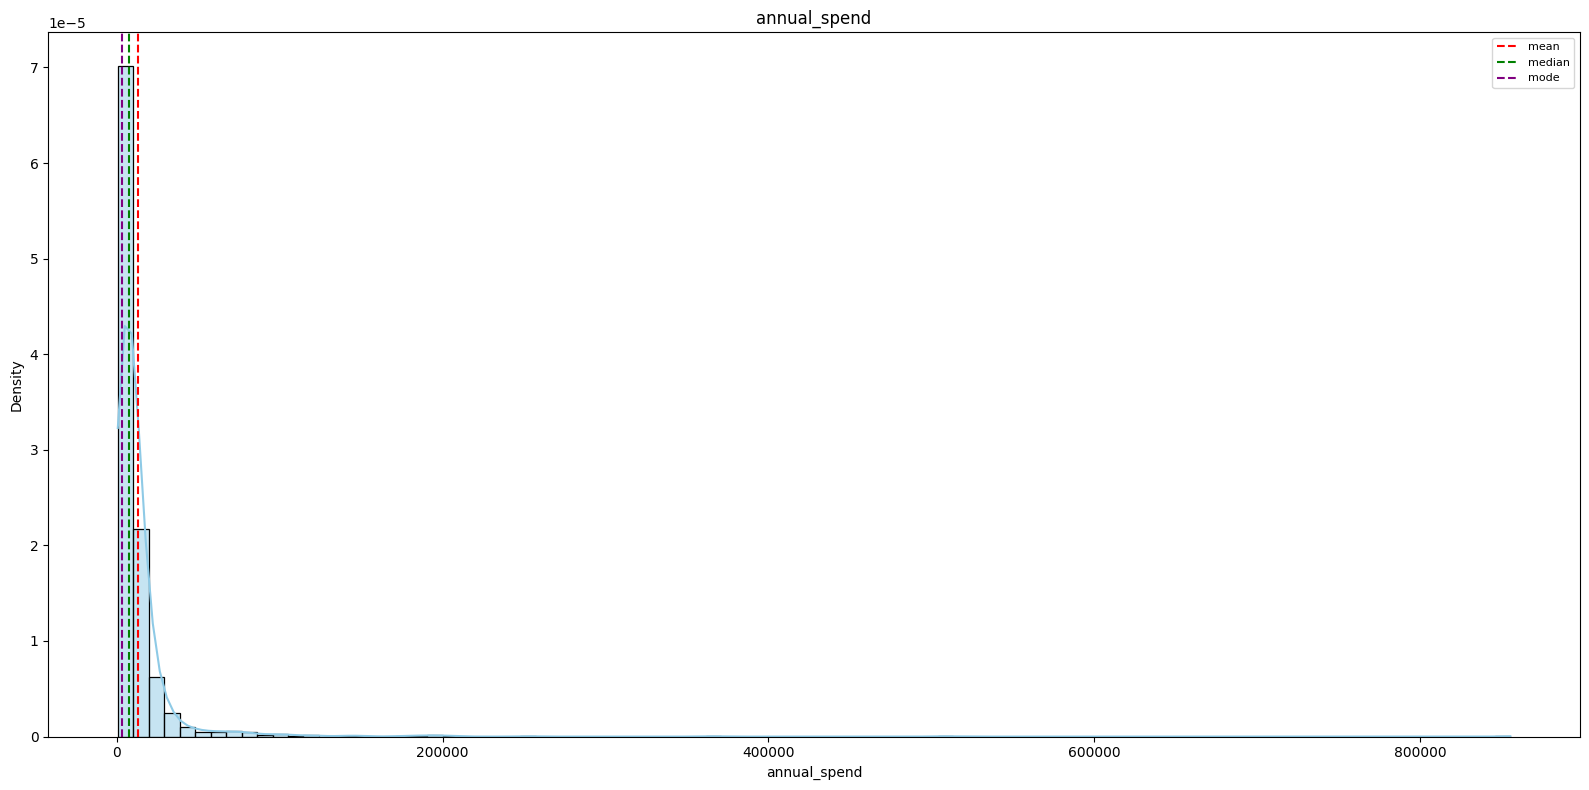

In [256]:
plt.figure(figsize=(16, 8))
sns.histplot(df['annual_spend'], kde=True, stat='density', color='#8ecae6')
plt.axvline(df['annual_spend'].mean(), color='red', linestyle='--', label='mean')
plt.axvline(df['annual_spend'].median(), color='green', linestyle='--', label='median')
plt.axvline(df['annual_spend'].round(0).mode()[0], color='purple', linestyle='--', label='mode')
plt.title('annual_spend'); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

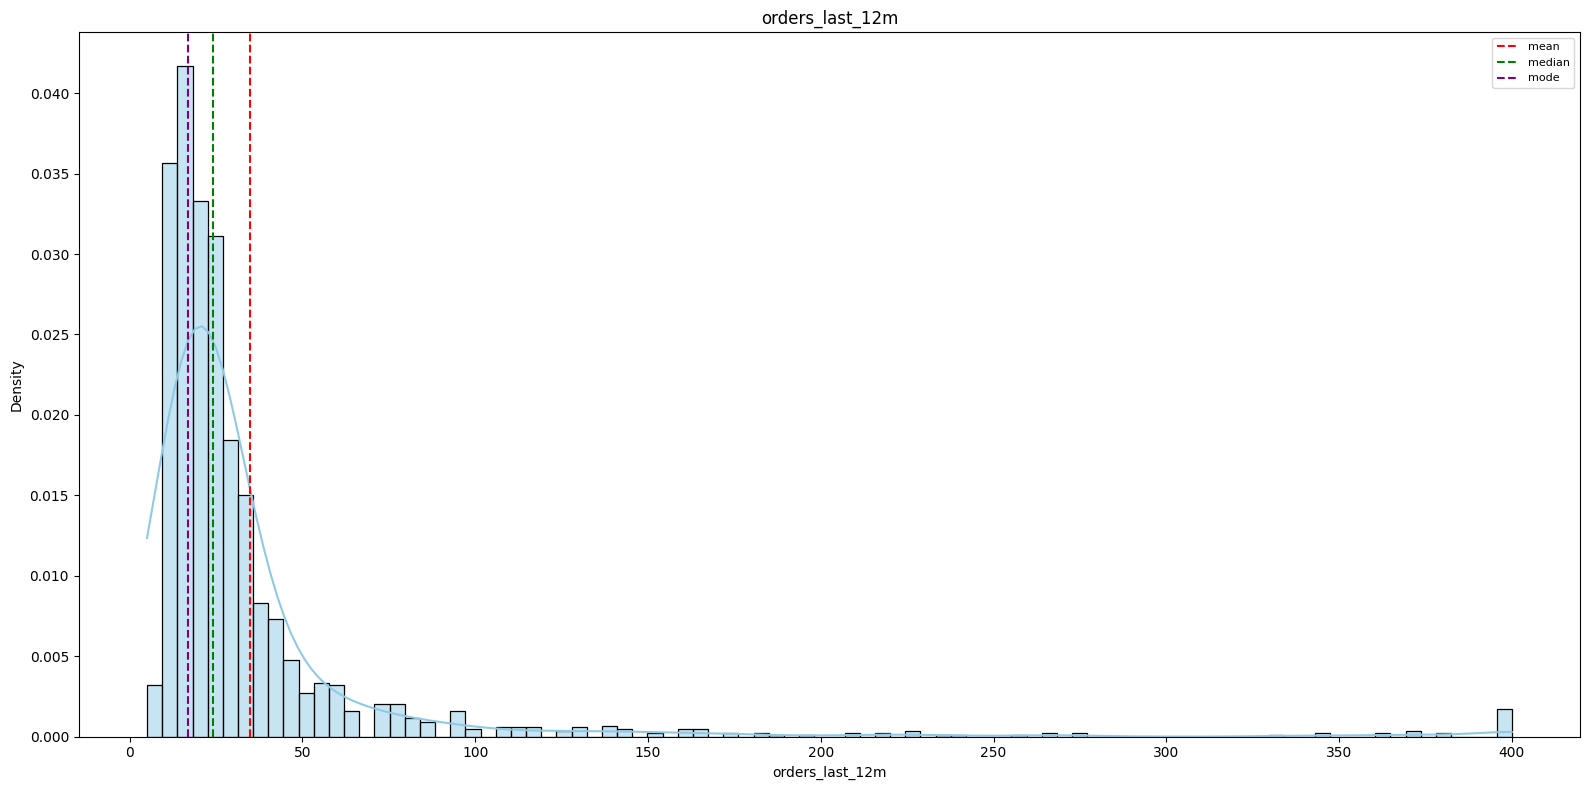

In [257]:
plt.figure(figsize=(16, 8))
sns.histplot(df['orders_last_12m'], kde=True, stat='density', color='#8ecae6')
plt.axvline(df['orders_last_12m'].mean(), color='red', linestyle='--', label='mean')
plt.axvline(df['orders_last_12m'].median(), color='green', linestyle='--', label='median')
plt.axvline(df['orders_last_12m'].round(0).mode()[0], color='purple', linestyle='--', label='mode')
plt.title('orders_last_12m'); plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [258]:
print(df[['age','customer_rating','delivery_time_min','avg_order_value','annual_spend','orders_last_12m']].skew().round(2))

age                   0.13
customer_rating      -1.82
delivery_time_min     1.07
avg_order_value       1.83
annual_spend         15.24
orders_last_12m       5.31
dtype: float64


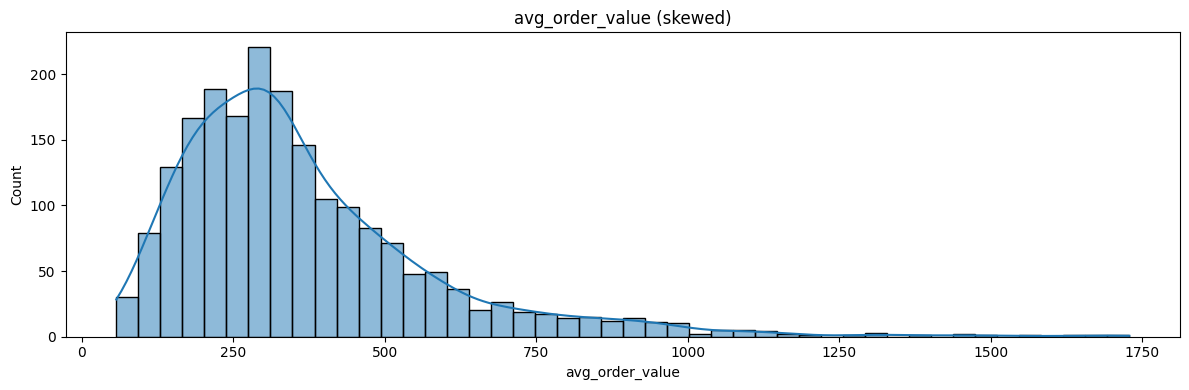

In [259]:
plt.figure(figsize=(12, 4))
sns.histplot(df['avg_order_value'], kde=True)
plt.title('avg_order_value (skewed)')
plt.tight_layout()
plt.show()

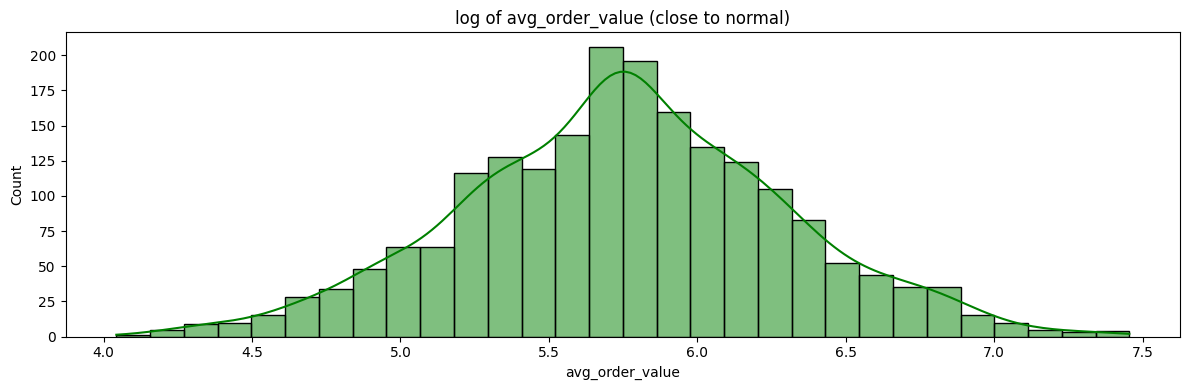

In [260]:
plt.figure(figsize=(12, 4))
sns.histplot(np.log(df['avg_order_value']), kde=True, color='green')
plt.title('log of avg_order_value (close to normal)')
plt.tight_layout()
plt.show()

**Why the order of mean/median/mode flips:**

The mean is pulled toward the tail, the mode sits at the peak, the median is in between.
- *Right-skewed* (tail on the right): **mode < median < mean**.
- *Left-skewed* (tail on the left, e.g. ratings piled near 5): **mean < median < mode**.
`avg_order_value` becomes roughly bell-shaped after `np.log`, the signature of a **log-normal** variable (many modest baskets, a few very large ones).

## Task 4: Relationships between variables

In [261]:
num = df.select_dtypes('number').drop(columns = ['delivery_extreme'])
display(num.cov().round(1))

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
city_tier,0.6,0.1,0.1,0.1,1.8,-20.2,-0.0,-0.2,0.4,0.9,-102.2
age,0.1,46.2,1.1,-0.4,4.6,17.3,-0.0,-16.0,-1.9,2.9,5433.4
tenure_months,0.1,1.1,99.6,-0.2,-0.6,-28.9,0.1,-0.2,-3.0,-7.7,-3633.6
app_sessions_per_month,0.1,-0.4,-0.2,14.3,-1.6,3.0,0.0,-0.9,1.9,14.0,9728.3
delivery_time_min,1.8,4.6,-0.6,-1.6,120.4,-90.9,0.0,-0.9,-2.1,-5.4,-2966.3
avg_order_value,-20.2,17.3,-28.9,3.0,-90.9,45826.0,0.8,-2.6,-146.1,214.0,1639299.4
customer_rating,-0.0,-0.0,0.1,0.0,0.0,0.8,0.3,-0.0,-0.7,-0.2,4.3
discount_used_pct,-0.2,-16.0,-0.2,-0.9,-0.9,-2.6,-0.0,85.3,-6.1,5.9,-8300.5
days_since_last_order,0.4,-1.9,-3.0,1.9,-2.1,-146.1,-0.7,-6.1,360.4,8.8,-9480.9
orders_last_12m,0.9,2.9,-7.7,14.0,-5.4,214.0,-0.2,5.9,8.8,2428.0,1083302.2


In [262]:
corr = num.corr()
display(corr.round(2))

,city_tier,age,tenure_months,app_sessions_per_month,delivery_time_min,avg_order_value,customer_rating,discount_used_pct,days_since_last_order,orders_last_12m,annual_spend
city_tier,1.00,0.01,0.02,0.02,0.21,-0.12,-0.00,-0.02,0.03,0.02,-0.00
age,0.01,1.00,0.02,-0.02,0.06,0.01,-0.01,-0.26,-0.01,0.01,0.03
tenure_months,0.02,0.02,1.00,-0.01,-0.01,-0.01,0.02,-0.00,-0.02,-0.02,-0.01
app_sessions_per_month,0.02,-0.02,-0.01,1.00,-0.04,0.00,0.01,-0.03,0.03,0.08,0.08
delivery_time_min,0.21,0.06,-0.01,-0.04,1.00,-0.04,0.01,-0.01,-0.01,-0.01,-0.01
avg_order_value,-0.12,0.01,-0.01,0.00,-0.04,1.00,0.01,-0.00,-0.04,0.02,0.25
customer_rating,-0.00,-0.01,0.02,0.01,0.01,0.01,1.00,-0.00,-0.07,-0.01,0.00
discount_used_pct,-0.02,-0.26,-0.00,-0.03,-0.01,-0.00,-0.00,1.00,-0.03,0.01,-0.03
days_since_last_order,0.03,-0.01,-0.02,0.03,-0.01,-0.04,-0.07,-0.03,1.00,0.01,-0.02
orders_last_12m,0.02,0.01,-0.02,0.08,-0.01,0.02,-0.01,0.01,0.01,1.00,0.72


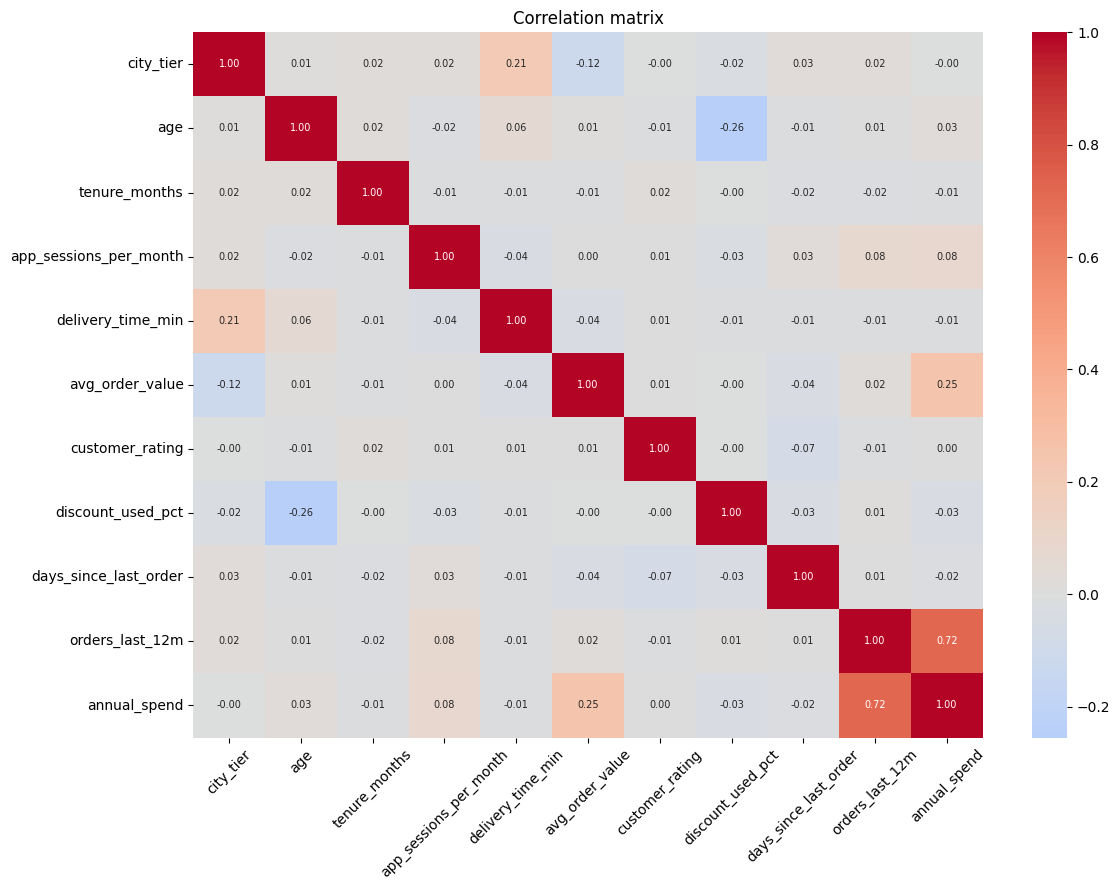

In [263]:
plt.figure(figsize = (12,9))
sns.heatmap(corr,annot = True, fmt = '.2f', cmap = 'coolwarm', center = 0, annot_kws = {'size':7})
plt.title('Correlation matrix')
plt.xticks(rotation = 45)
plt.tight_layout()
plt.show()

**Covariance vs correlation:** covariance depends on the units of the two variables, so its size can't be compared between pairs. Correlation is always between −1 and +1, so strength and direction are easy to compare.

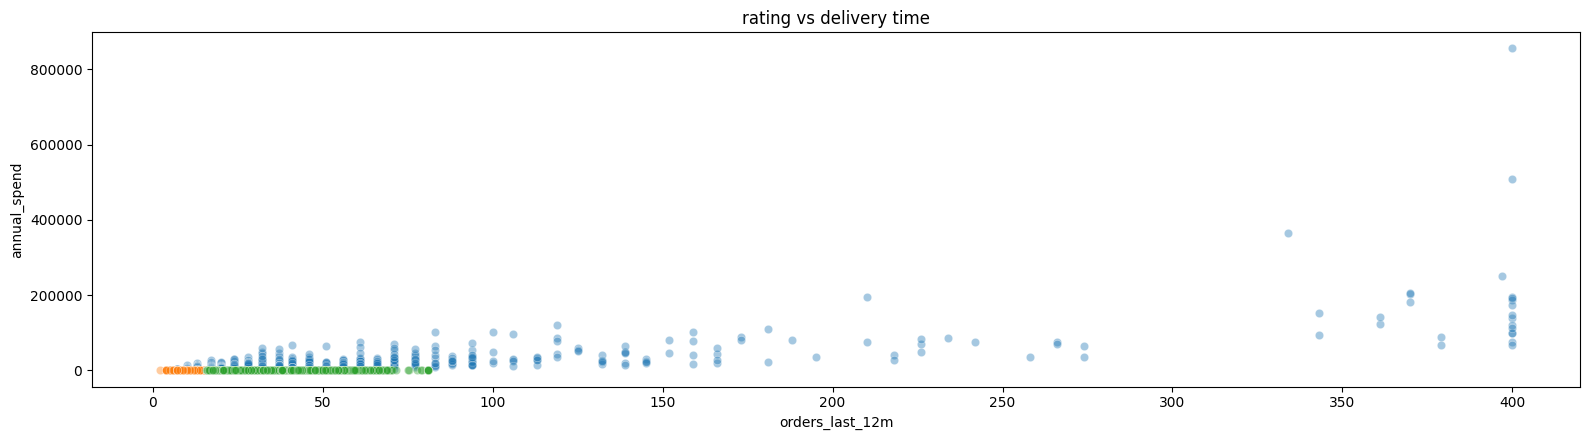

In [264]:
plt.figure(figsize=(16, 4.5))
sns.scatterplot(x='orders_last_12m', y='annual_spend', data=df, alpha=0.4)
plt.title('annual_spend vs orders_last_12m')
sns.scatterplot(x='app_sessions_per_month', y='orders_last_12m', data=df, alpha=0.4)
plt.title('orders vs app sessions')
sns.scatterplot(x='delivery_time_min', y='customer_rating', data=df, alpha=0.4)
plt.title('rating vs delivery time')
plt.tight_layout()
plt.show()

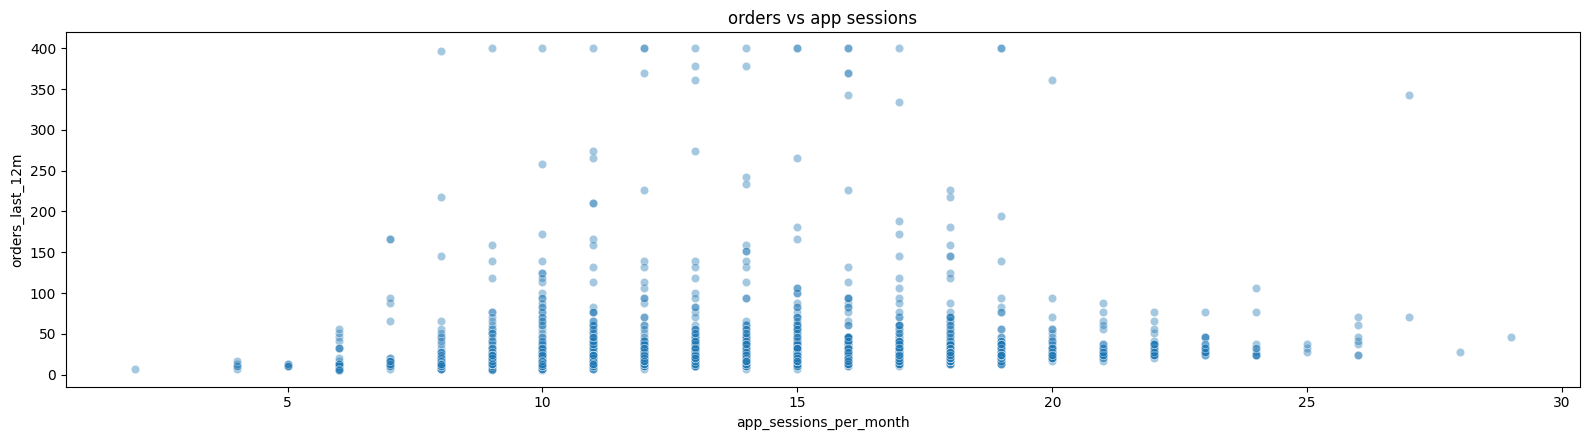

In [265]:
plt.figure(figsize=(16, 4.5))
sns.scatterplot(x='app_sessions_per_month', y='orders_last_12m', data=df, alpha=0.4)
plt.title('orders vs app sessions')
plt.tight_layout()
plt.show()

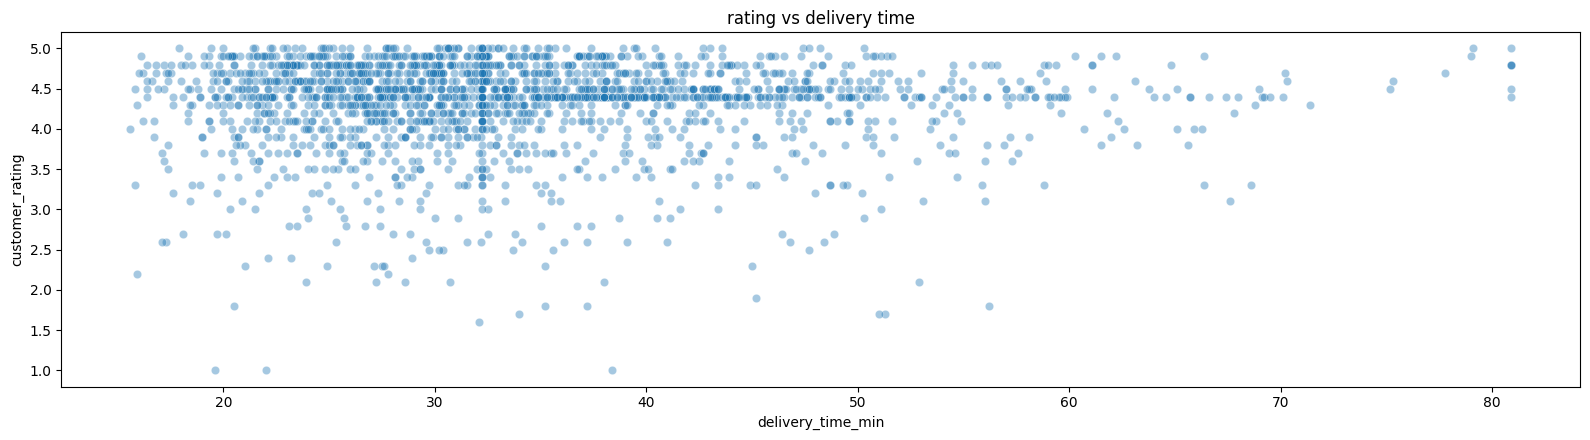

In [266]:
plt.figure(figsize=(16, 4.5))
sns.scatterplot(x='delivery_time_min', y='customer_rating', data=df, alpha=0.4)
plt.title('rating vs delivery time')
plt.tight_layout()
plt.show()

In [267]:
df['signup_month'] = df['signup_date'].dt.to_period('M')
signups = df.groupby('signup_month').size()
avg_delivery = df.groupby('signup_month')['delivery_time_min'].mean()

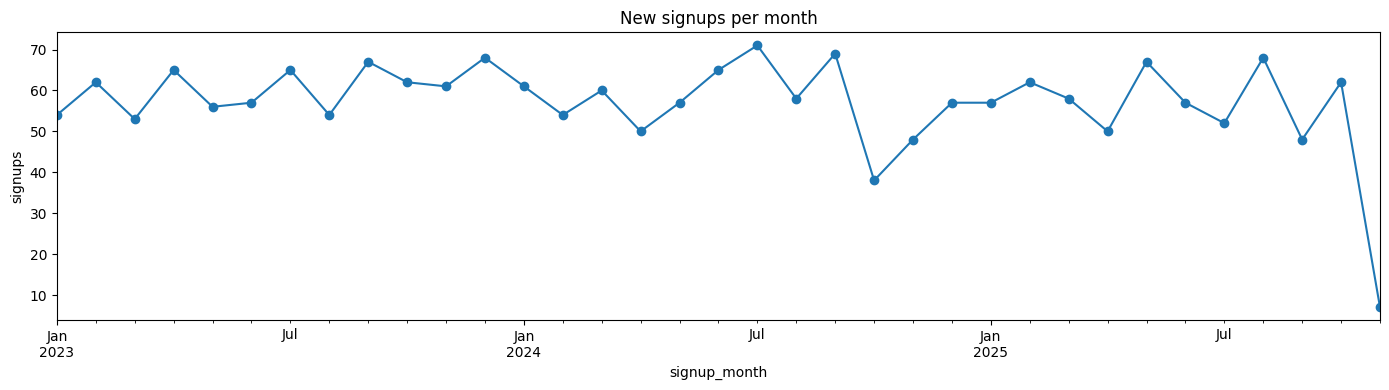

In [268]:
plt.figure(figsize=(14, 4))
signups.plot(marker='o')
plt.title('New signups per month')
plt.ylabel('signups')
plt.tight_layout()
plt.show()

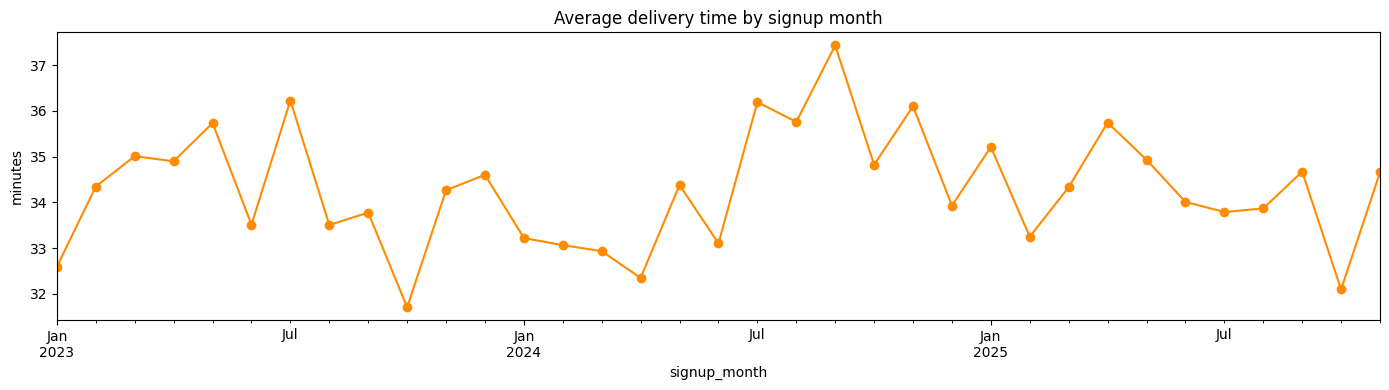

In [269]:
plt.figure(figsize=(14, 4))
avg_delivery.plot(marker='o', color='darkorange')
plt.title('Average delivery time by signup month')
plt.ylabel('minutes')
plt.tight_layout()
plt.show()

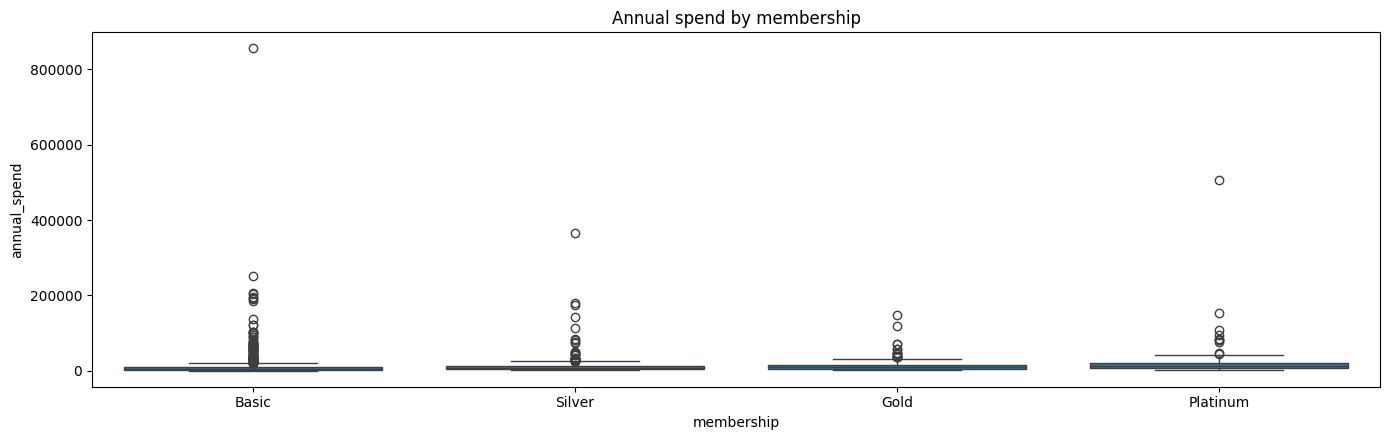

In [270]:
plt.figure(figsize=(14, 4.5))
sns.boxplot(x='membership', y='annual_spend', data = df, order = ['Basic', 'Silver', 'Gold', 'Platinum'])
plt.title('Annual spend by membership')
plt.tight_layout()
plt.show()

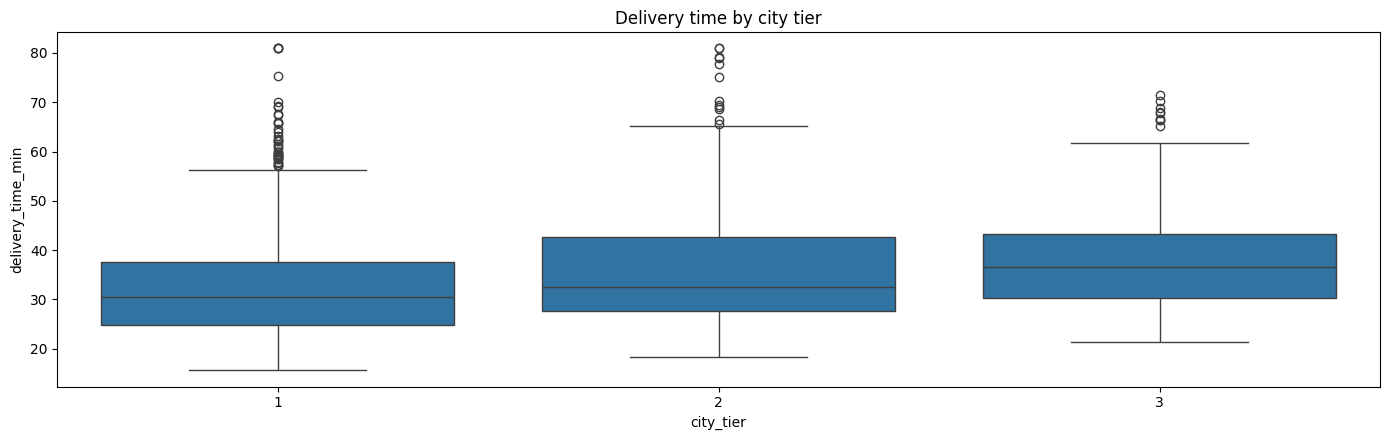

In [271]:
plt.figure(figsize=(14, 4.5))
sns.boxplot(x='city_tier', y='delivery_time_min', data = df)
plt.title('Delivery time by city tier')
plt.tight_layout()
plt.show()

In [272]:
top = corr['annual_spend'].drop('annual_spend').sort_values(key = abs, ascending = False)
display(top.round(2).to_frame('corr with annual_spend').head(6))

,corr with annual_spend
orders_last_12m,0.72
avg_order_value,0.25
app_sessions_per_month,0.08
discount_used_pct,-0.03
age,0.03
days_since_last_order,-0.02


**Does correlation prove causation?**

No. More orders and higher spend move together, but that is partly by construction (spend ≈ orders × basket). Other links (e.g. sessions ↔ orders) could be driven by a hidden factor such as customer enthusiasm. Only an experiment would show cause.

## Task 5: Encoding categorical variables

In [273]:
enc = df.copy()
enc['membership_label'] = enc.membership.map({'Basic':0, 'Silver':1, 'Gold':2, 'Platinum':3})
oh = pd.get_dummies(enc[['device_type','acquisition_channel']],drop_first = True, dtype = int)
enc['city_target_enc'] = enc.groupby('city').annual_spend.transform('mean').round(0)
enc['city_alpha_label'] = enc.city.astype('category').cat.codes   # what NOT to do
display(pd.concat([enc[['membership', 'membership_label', 'city', 'city_alpha_label', 'city_target_enc']], oh], axis = 1).head(8))
print('one-hot columns with drop_first=True:', list(oh.columns))
print('without drop_first:', pd.get_dummies(enc[['device_type','acquisition_channel']]).shape[1],'columns')

,membership,membership_label,city,city_alpha_label,city_target_enc,device_type_Web,device_type_iOS,acquisition_channel_Organic,acquisition_channel_Paid Social,acquisition_channel_Referral,acquisition_channel_Search Ads
0,Basic,0,Lucknow,6,13940.0,0,0,0,0,1,0
1,Basic,0,Bengaluru,0,12004.0,0,1,0,0,0,0
2,Basic,0,Indore,3,10733.0,0,1,0,0,1,0
3,Basic,0,Jaipur,4,10411.0,0,0,0,1,0,0
4,Basic,0,Mumbai,7,12021.0,0,0,0,0,0,1
5,Basic,0,Kochi,5,15740.0,0,0,0,1,0,0
6,Silver,1,Lucknow,6,13940.0,0,1,0,0,0,1
7,Basic,0,Lucknow,6,13940.0,0,1,1,0,0,0


one-hot columns with drop_first=True: ['device_type_Web', 'device_type_iOS', 'acquisition_channel_Organic', 'acquisition_channel_Paid Social', 'acquisition_channel_Referral', 'acquisition_channel_Search Ads']
without drop_first: 8 columns


- **Label/ordinal** fits `membership` because Basic < Silver < Gold < Platinum is a real order.
- **Alphabetical label encoding of `city`** is misleading: it tells a model Bengaluru(0) < Delhi(1) < … as if numeric distance meant something.
- **One-hot** avoids false order but 10 cities → 10 columns (wide). `drop_first=True` avoids the **dummy variable trap** (the dropped category is implied by all zeros, so columns aren't perfectly redundant).
- **Target encoding** gives one compact column, but it uses `annual_spend` to build a feature that may later predict `annual_spend` → **leakage**, especially for small categories. It should be computed on training data only.

## Task 6: Central tendency and percentiles

In [274]:
print('age             -> mean', round(df['age'].mean(), 1), '| median', df['age'].median(), '| mode', df['age'].mode()[0])
print('orders_last_12m -> mean', round(df['orders_last_12m'].mean(), 1), '| median', df['orders_last_12m'].median(), '| mode', df['orders_last_12m'].mode()[0])
print('annual_spend    -> mean', round(df['annual_spend'].mean()), '| median', round(df['annual_spend'].median()), '| mode', df['annual_spend'].mode()[0])
print('membership      -> mode', df['membership'].mode()[0])

print(df[['delivery_time_min', 'annual_spend']].quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).round(1))

age             -> mean 31.9 | median 32.0 | mode 32.0
orders_last_12m -> mean 34.9 | median 24.0 | mode 17
annual_spend    -> mean 12996 | median 7142 | mode 2916.0
membership      -> mode Basic
      delivery_time_min  annual_spend
0.10               22.1        2508.6
0.25               26.5        4085.8
0.50               32.2        7142.0
0.75               40.1       12781.2
0.90               49.2       22453.7
0.95               55.4       35355.2
0.99               68.6      109149.8


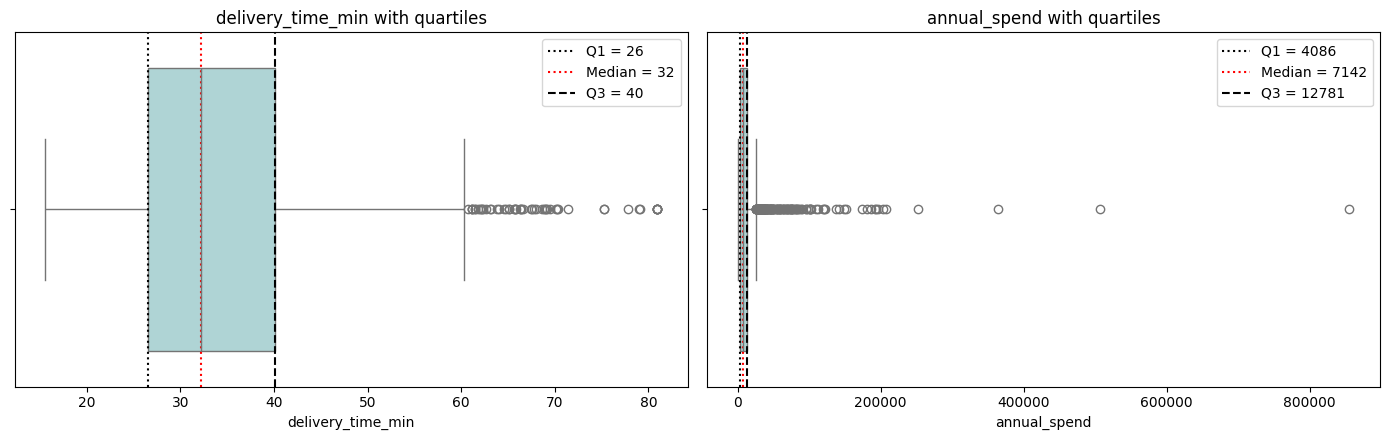

In [275]:
plt.figure(figsize=(14, 4.5))

plt.subplot(1, 2, 1)
sns.boxplot(x=df['delivery_time_min'], color='#a8dadc')
plt.axvline(df['delivery_time_min'].quantile(0.25), color='k', linestyle=':', label='Q1 = ' + str(round(df['delivery_time_min'].quantile(0.25))))
plt.axvline(df['delivery_time_min'].median(), color='red', linestyle=':', label='Median = ' + str(round(df['delivery_time_min'].median())))
plt.axvline(df['delivery_time_min'].quantile(0.75), color='k', linestyle='--', label='Q3 = ' + str(round(df['delivery_time_min'].quantile(0.75))))
plt.title('delivery_time_min with quartiles'); plt.legend()

plt.subplot(1, 2, 2)
sns.boxplot(x=df['annual_spend'], color='#a8dadc')
plt.axvline(df['annual_spend'].quantile(0.25), color='k', linestyle=':', label='Q1 = ' + str(round(df['annual_spend'].quantile(0.25))))
plt.axvline(df['annual_spend'].median(), color='red', linestyle=':', label='Median = ' + str(round(df['annual_spend'].median())))
plt.axvline(df['annual_spend'].quantile(0.75), color='k', linestyle='--', label='Q3 = ' + str(round(df['annual_spend'].quantile(0.75))))
plt.title('annual_spend with quartiles'); plt.legend()
plt.tight_layout()
plt.show()

In [276]:
p90 = df['delivery_time_min'].quantile(0.90)
print('90% of customers get their delivery in', round(p90, 1), 'minutes or less (P90).')
print('annual_spend mean is', round(df['annual_spend'].mean() / df['annual_spend'].median(), 2), 'times its median.')

90% of customers get their delivery in 49.2 minutes or less (P90).
annual_spend mean is 1.82 times its median.


**Why mean ≫ median for spend:**

A minority of very heavy spenders pulls the mean up while the median stays at the typical customer. For the business, the *average* customer is not typical, so budgets, targets and offers based on the mean will overestimate what a normal customer is worth. Segmenting heavy users separately is more useful.